# alloc_v2 综合 Dashboard

只读 `data/alloc_v2/`，不打网。先刷新：

```bash
./scripts/run_alloc_v2.sh update   # 日常
./scripts/run_alloc_v2.sh all --start 2018-01-01   # 首次
```

**口径**：价格/活跃度 ≠ 流入；份额变化 ≠ 净流入；北向净买额仅供对照；估算必须当估算看。  
每张图下方有「读图」说明。

In [10]:
from pathlib import Path
import importlib
import sys

import matplotlib.pyplot as plt
import pandas as pd

ROOT = Path("../..").resolve()
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

# 强制重载，避免内核里还是改代码前的旧 plotting
import qlib.contrib.data.alloc_v2.labels as _labels
import qlib.contrib.data.alloc_v2.plotting as P

importlib.reload(_labels)
importlib.reload(P)

from qlib.contrib.data.alloc_v2.paths import default_root
from qlib.contrib.data.alloc_v2.report import dashboard_payload

pd.set_option("display.max_rows", 40)
pd.set_option("display.max_columns", 20)
pd.set_option("display.width", 160)

print("字体:", P.configure_cjk_font())
DATA = default_root()
print("数据根:", DATA)
payload = dashboard_payload(DATA)
standard = payload["standard"]
factors = payload["factors"]
swing = payload["swing"]
print("标准层行数", len(standard), "因子行数", len(factors))

字体: PingFang SC
数据根: /Users/900game/Desktop/ai/qlib/data/alloc_v2
标准层行数 277642 因子行数 331296


## 1. 全球跨资产（代理）

指数与收益率描述定价环境，不是资金流。

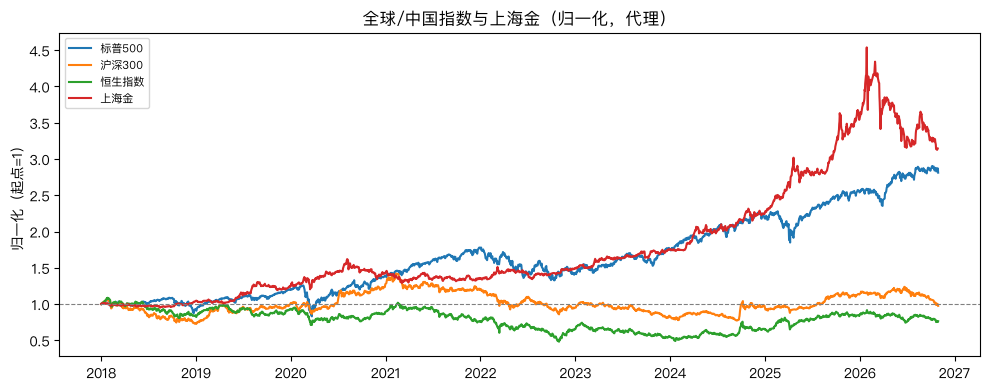

【读图】比较全球/中国主要股指与上海金的相对走势（起点=1）。
曲线上行表示相对起点上涨更多；彼此背离只说明相对强弱。
注意：这是价格代理，不是资金净流入，也不能证明跨市场资金转移。


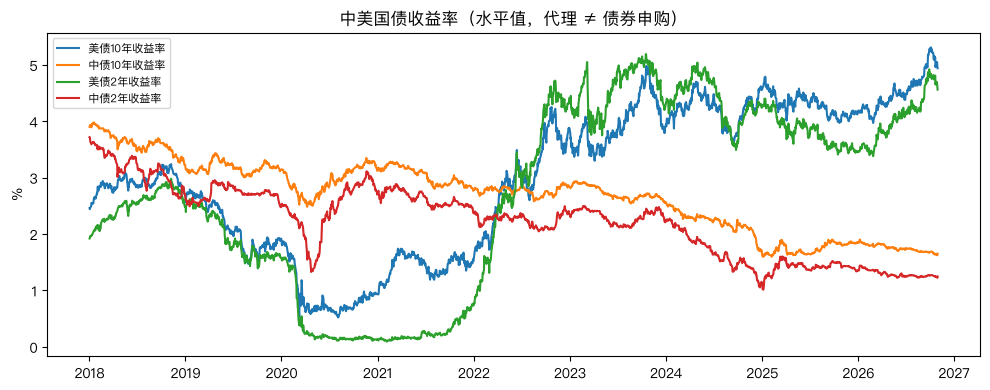

【读图】中美国债收益率水平（未归一化）。
收益率上行通常对应利率收紧/定价更贵；可用来解释风险资产环境。
注意：收益率变动不是债券基金申购量。


In [11]:
global_map = {
    "SPX": P.series_from_standard(standard, dataset="idx_global", entity_id="SPX", field="close"),
    "CSI300": P.series_from_standard(standard, dataset="idx_global", entity_id="CSI300", field="close"),
    "HSI": P.series_from_standard(standard, dataset="idx_global", entity_id="HSI", field="close"),
    "SGE_GOLD": P.series_from_standard(standard, dataset="gold_sge", entity_id="SGE_GOLD", field="close"),
}
fig = P.plot_normalized(global_map, title="全球/中国指数与上海金（归一化，代理）")
plt.show()
P.print_caption("global_index")

yield_map = {
    "US10Y": P.series_from_standard(standard, dataset="yield_cn_us", entity_id="US10Y", field="yield"),
    "CN10Y": P.series_from_standard(standard, dataset="yield_cn_us", entity_id="CN10Y", field="yield"),
    "US2Y": P.series_from_standard(standard, dataset="yield_cn_us", entity_id="US2Y", field="yield"),
    "CN2Y": P.series_from_standard(standard, dataset="yield_cn_us", entity_id="CN2Y", field="yield"),
}
fig = P.plot_levels(yield_map, title="中美国债收益率（水平值，代理 ≠ 债券申购）", ylabel="%")
plt.show()
P.print_caption("yield_cn_us")

## 2. 北向：成交与持股

主看成交额与持股市值；净买额单独一图且仅供对照。

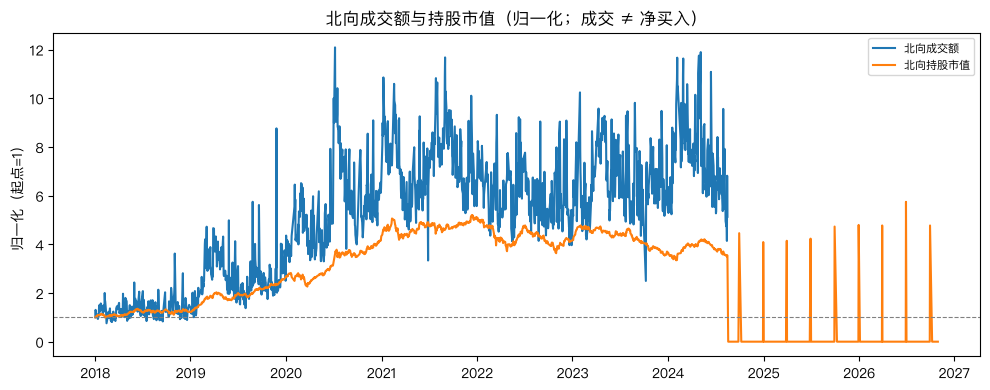

【读图】北向成交额与持股市值的相对变化（起点=1）。
成交升=通道更活跃；持股市值升可能含股价上涨，不一定等于多买。
注意：成交额≠净买入；这是核心观察图，优先于净买额。


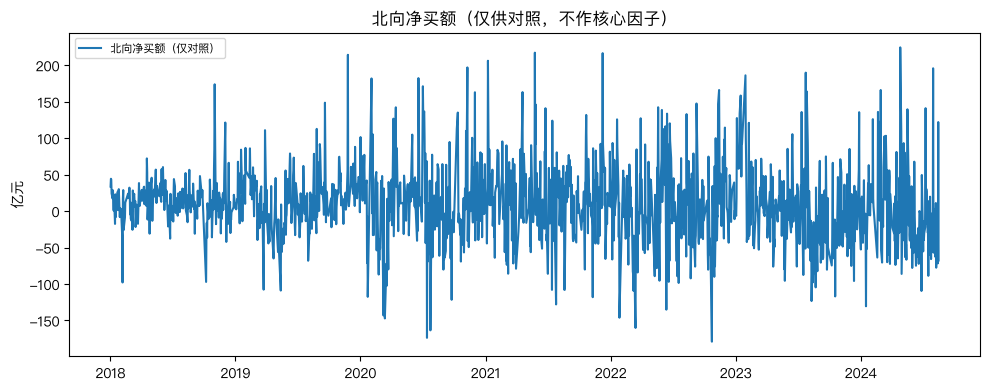

【读图】北向成交净买额，仅作历史对照。
披露口径曾调整，不能当作当前完整实时外资流量。
注意：本序列不作 S1–S4 核心因子（reference_only）。


In [12]:
nb_core = {
    "NORTH_amount": P.series_from_standard(standard, dataset="hsgt_turnover", entity_id="NORTH", field="amount"),
    "NORTH_hold": P.series_from_standard(standard, dataset="hsgt_hold", entity_id="NORTH", field="hold_mcap"),
}
fig = P.plot_normalized(nb_core, title="北向成交额与持股市值（归一化；成交 ≠ 净买入）")
plt.show()
P.print_caption("north_core")

nb_ref = {
    "NORTH_net_buy": P.series_from_standard(standard, dataset="hsgt_net", entity_id="NORTH", field="net_buy"),
}
fig = P.plot_levels(nb_ref, title="北向净买额（仅供对照，不作核心因子）", ylabel="亿元")
plt.show()
P.print_caption("north_net_ref")

## 3. 行业配置

综合分为估算；成交占比为代理。权重先均等，样本外再估。

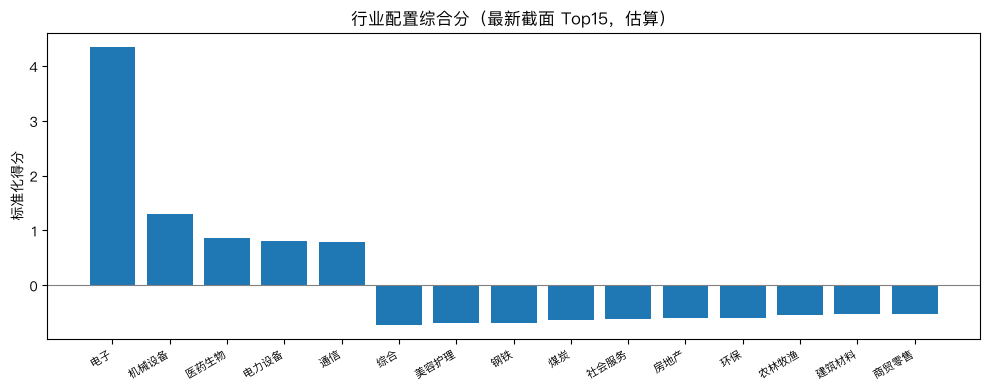

【读图】行业配置综合分最新截面 Top（估算）。
分高=相对其它行业更「热/强」的综合分（当前等权组件）。
注意：不是净流入金额，也不是买卖指令；权重需样本外再估。


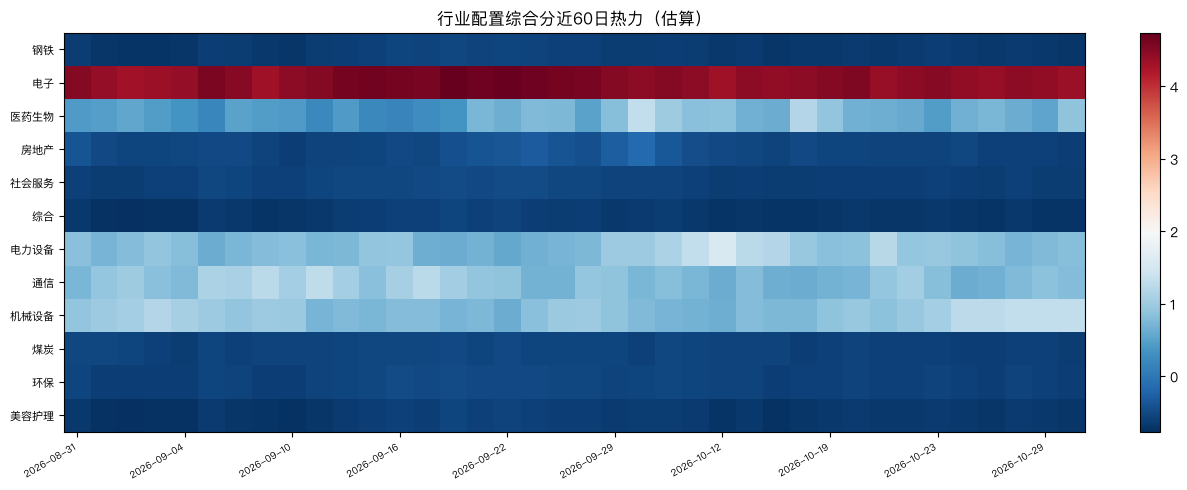

【读图】行业配置综合分近60日热力。
颜色持续偏强=主题有持续性；突然变色=切换或回撤。
注意：仍是估算/代理合成，不能单独当作资金流证据。


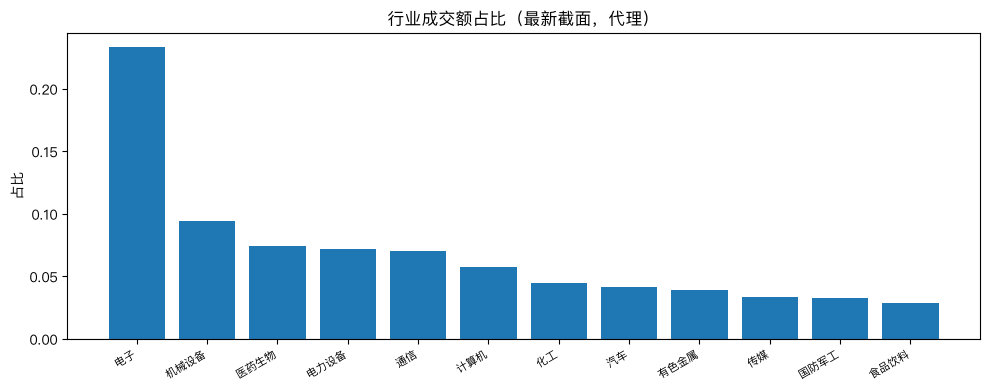

【读图】各行业成交额占全市场比例（代理）。
占比升高=交易更集中于此行业。
注意：成交活跃≠净申购或净流入。


In [13]:
score_top = P.latest_cross_section(factors, "IndustryAllocationScore", top_n=15)
fig = P.plot_bar(
    list(score_top.index.astype(str)),
    list(score_top.values),
    title="行业配置综合分（最新截面 Top15，估算）",
    ylabel="标准化得分",
)
plt.show()
P.print_caption("industry_score_bar")

fig = P.plot_heatmap_pivot(
    factors,
    "IndustryAllocationScore",
    title="行业配置综合分近60日热力（估算）",
    last_n_days=60,
)
plt.show()
P.print_caption("industry_score_heat")

turn_top = P.latest_cross_section(factors, "Industry_Turnover_Ratio", top_n=12)
fig = P.plot_bar(
    list(turn_top.index.astype(str)),
    list(turn_top.values),
    title="行业成交额占比（最新截面，代理）",
    ylabel="占比",
)
plt.show()
P.print_caption("industry_turnover")

## 4. ETF 三类指标

份额变化与估算配置并列；估算 ≠ 现金净流入。

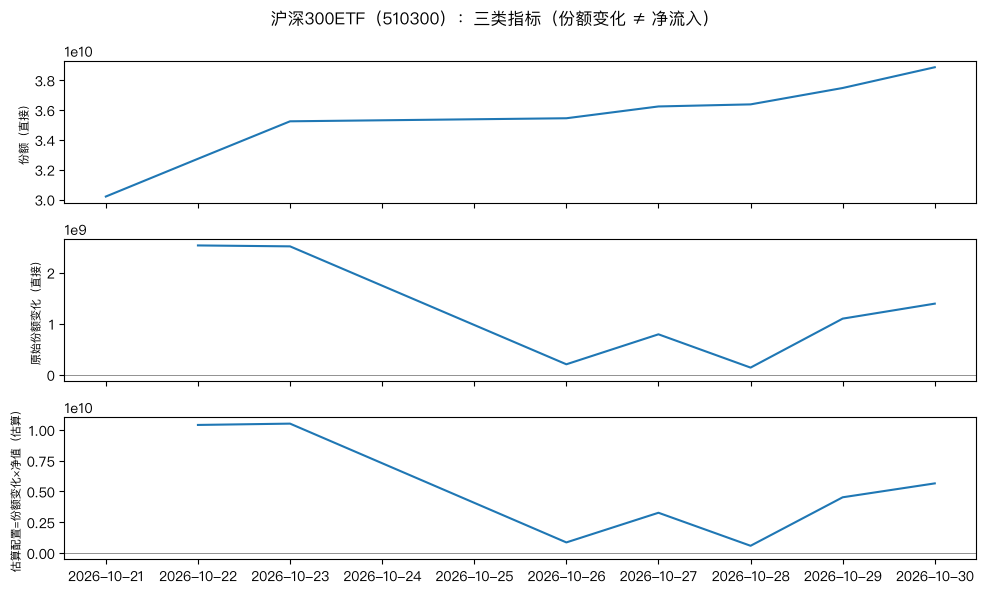

【读图】沪深300ETF 三类指标：份额、份额变化、估算配置。
份额升接近净申购方向；估算配置=份额变化×净值，是估算不是现金转账。
注意：价格大涨而份额下降时，更像涨价驱动，不要写成「资金流入」。


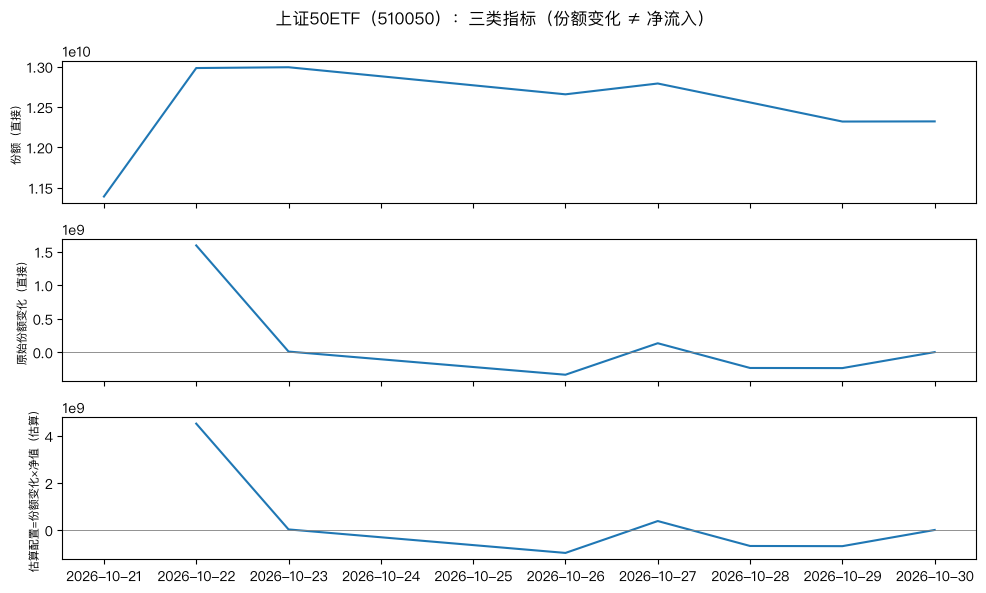

【读图】上证50ETF 三类指标：份额、份额变化、估算配置。
读法同沪深300ETF：并列看份额与价格是否背离。
注意：估算配置必须当作 estimate，不是已证实净流入。


,代码,折溢价,质量标记,名称
3150,159915,0.002305,ok,创业板ETF(159915)
5290,159922,0.000978,ok,159922
7430,510050,0.000664,share_price_diverge,上证50ETF(510050)
9570,510300,0.001010,share_price_diverge,沪深300ETF(510300)
11710,510500,-0.000032,share_price_diverge,中证500ETF(510500)
13850,510880,0.000347,ok,510880
15989,511260,-0.000391,ok,511260
16463,512050,0.000000,share_price_diverge,512050
18602,512100,-0.000598,share_price_diverge,中证1000ETF(512100)
20393,512480,0.001252,share_price_diverge,512480


【读图】套利/折溢价风险标记快照。
折溢价过大、换手异常、份额与价格背离时，份额变化噪音更大。
注意：有风险标记时，降低对「份额=流入」的信任。


In [14]:
fig = P.plot_etf_three_metrics(factors, "510300")
plt.show()
P.print_caption("etf_three_510300")

fig = P.plot_etf_three_metrics(factors, "510050")
plt.show()
P.print_caption("etf_three_510050")

arb = factors[factors["factor_id"] == "ArbitrageRisk"].copy() if not factors.empty else pd.DataFrame()
if not arb.empty:
    arb["event_date"] = pd.to_datetime(arb["event_date"])
    last = arb["event_date"].max()
    snap = arb[arb["event_date"] == last][["entity_id", "value", "quality_flag"]].head(20).copy()
    from qlib.contrib.data.alloc_v2.labels import display_name

    snap["名称"] = snap["entity_id"].map(display_name)
    display(snap.rename(columns={"entity_id": "代码", "value": "折溢价", "quality_flag": "质量标记"}))
else:
    print("暂无套利风险标记")
P.print_caption("etf_arb")

## 5. 信号 S1–S4

三级独立计算再交叉。S1 未过则 S4 不成立。

,signal_id,value,statement_kind,components,asof,notes
0,S1,0.0,signal,"{'above_ma': False, 'active': True, 'strength'...",2026-11-01,参数待验；市场层独立计算


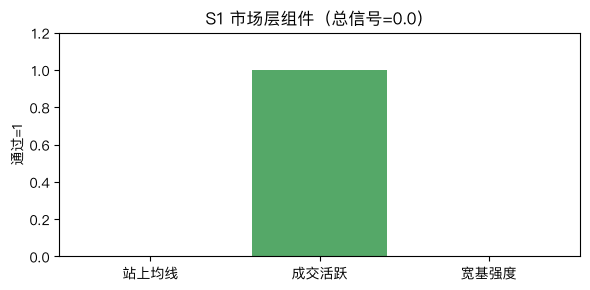

【读图】S1 市场层组件：绿=通过，红=未通过。
需宽基强度、均线、成交活跃等条件组合判断；总信号为 0 表示市场层未放行。
注意：S1 未过时，即使有行业过 S2，S4 三层共振也不成立；不是买卖信号。


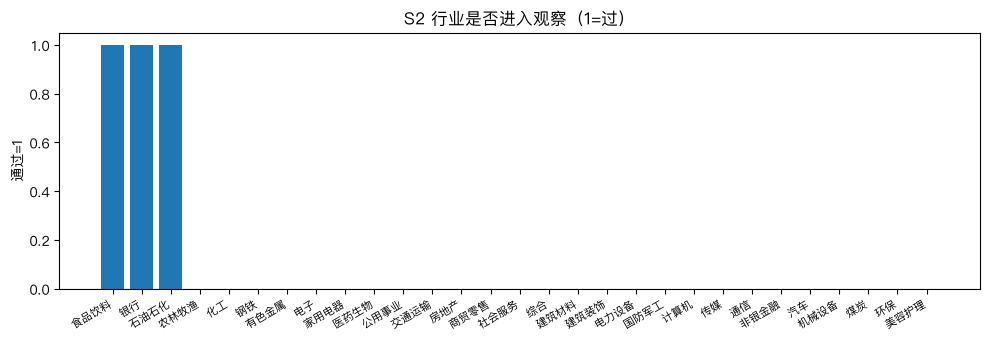

【读图】S2 行业是否进入观察名单（1=过）。
通过表示行业层条件满足，可进入观察，不等于建议买入。
注意：须结合 S1；S1=0 时此处亮灯只作观察。


,asof,entity_id,signal_id,value,statement_kind,available_at,quality_flag,notes,version
0,2026-11-01,MARKET,S4,0.0,signal,2026-11-01,ok,S1 failed,signals@v2


【读图】S4 为市场+行业(+个股确认)同时成立。
entity 为 MARKET/NONE 且值为 0，表示共振未成立。
注意：这是研究信号，不是实盘下单指令。


,rule_id,signal_id,condition,action,tuned_on
0,S1_ma_break,S1,broad_etf_below_ma60,clear_S4,none
1,S2_flow_fade,S2,IndustryETFFlow20_pct120 < 0.4,drop_industry,none
2,S3_lhb_expire,S3,LHB decay to NA,drop_stock_confirm,none


In [15]:
s1 = swing["S1"]
s2 = swing["S2"]
s4 = swing["S4"]
display(s1)
fig = P.plot_s1_components(s1)
plt.show()
P.print_caption("s1")

fig = P.plot_s2_pass_bar(s2)
plt.show()
P.print_caption("s2")

display(s4)
P.print_caption("s4")
display(swing.get("invalidation", pd.DataFrame()))

## 6. 回测记录

红柱表示该因子计算失败或缺失；失败结果也会保留。

,factor_id,status,failures,version,rank_ic_mean_h5,rank_ic_ir_h5,long_short_mean_h5,long_short_net_h5,rank_ic_mean_h10,rank_ic_ir_h10,long_short_mean_h10,long_short_net_h10,rank_ic_mean_h20,rank_ic_ir_h20,long_short_mean_h20,long_short_net_h20,rank_ic_mean_h40,rank_ic_ir_h40,long_short_mean_h40,long_short_net_h40
0,IndustryAllocationScore,ok,,v2,0.001178,0.003929,-0.000200,-0.002200,0.001804,0.005895,-0.000359,-0.002359,-0.006929,-0.022008,-0.000735,-0.002735,-0.011713,-0.036031,0.000625,-0.001375
1,IndustryETFFlow20,failed,factor_missing,v2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,Industry_Turnover_Ratio,ok,,v2,0.001178,0.003929,-0.000200,-0.002200,0.001804,0.005895,-0.000359,-0.002359,-0.006929,-0.022008,-0.000735,-0.002735,-0.011713,-0.036031,0.000625,-0.001375
3,Industry_RelRet20,ok,,v2,0.008807,0.026668,0.001531,-0.000469,0.014854,0.045721,0.002316,0.000316,-0.001379,-0.004384,0.001520,-0.000480,-0.030383,-0.096834,0.000380,-0.001620
4,LHB_Institution_Ratio,failed,factor_missing,v2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


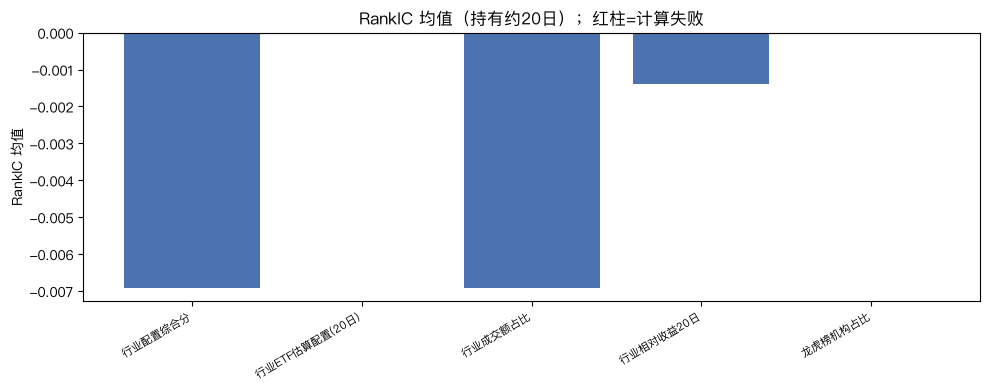

【读图】因子与未来约20日收益的截面 RankIC 均值。
接近 0 表示这段样本几乎没有稳定预测力；红柱=该因子计算失败/缺失。
注意：失败≠很差的 IC，而是没有结果；不能把监测看板当成已验证 alpha。


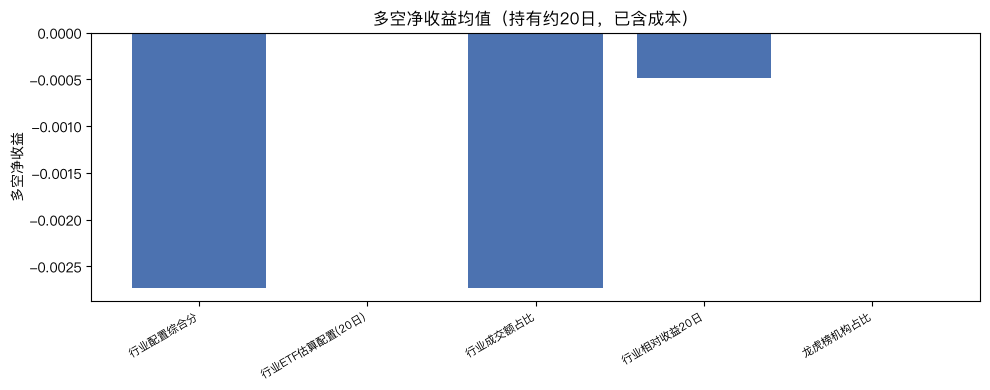

【读图】高分组减低分组的多空收益均值（已扣粗成本）。
净值为负或接近 0，说明当前参数下难有稳定超额。
注意：失败结果也会留档；不要只看最优组合。


In [16]:
bt = swing["backtest"]
display(bt)
fig = P.plot_backtest_bars(
    bt,
    metric="rank_ic_mean_h20",
    title="RankIC 均值（持有约20日）；红柱=计算失败",
    ylabel="RankIC 均值",
)
plt.show()
P.print_caption("backtest_ic")

fig = P.plot_backtest_bars(
    bt,
    metric="long_short_net_h20",
    title="多空净收益均值（持有约20日，已含成本）",
    ylabel="多空净收益",
)
plt.show()
P.print_caption("backtest_ls")